# Illustrative figures

Synthetic examples for Figures 2, 3, 6 and 7 of the paper. Each cell sets its own plotting style and writes one PDF to this directory.

## Figure 2: risk space and utility space

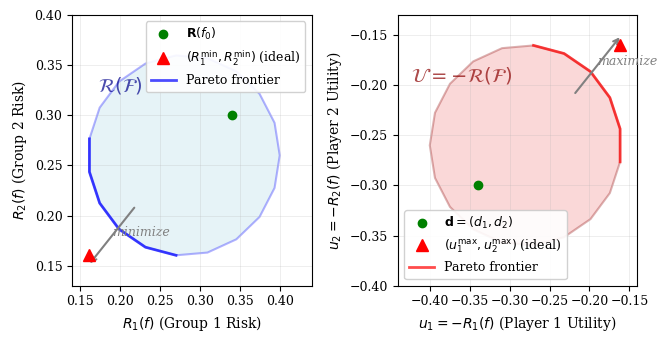

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import matplotlib.patches as mpatches

# Set matplotlib parameters for ICML
plt.rcdefaults()
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 9  # ICML caption size as base
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['lines.linewidth'] = 0.75  # At least 0.5 points

# Set up the figure - for 2-column layout spanning both columns
# ICML typical column width is ~3.25in, so full width ~6.75in
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.75, 3.5))

# Generate smoother, more rounded feasible set
np.random.seed(42)
# Create points on an ellipse-like shape for smoother boundary
theta = np.linspace(0, 2*np.pi, 20)
center = np.array([0.28, 0.26])
a, b = 0.12, 0.10  # semi-axes
risk_points = np.column_stack([
    center[0] + a * np.cos(theta),
    center[1] + b * np.sin(theta)
])

# Compute convex hull
from scipy.spatial import ConvexHull
hull = ConvexHull(risk_points)
hull_points = risk_points[hull.vertices]

# ===== LEFT PANEL: Risk Space =====
ax1.set_xlabel(r'$R_1(f)$ (Group 1 Risk)')
ax1.set_ylabel(r'$R_2(f)$ (Group 2 Risk)')
# No title - following ICML guidelines

# Plot feasible set
poly1 = Polygon(hull_points, alpha=0.3, facecolor='lightblue', edgecolor='blue', linewidth=1.5)
ax1.add_patch(poly1)

# Add text in upper left of the feasible set
ax1.text(0.20, 0.33, r'$\mathcal{R}(\mathcal{F})$', fontsize=14, 
         ha='center', va='center', style='italic', color='darkblue', alpha=0.7)

# Disagreement point (baseline) - inside the set (now green and smaller)
d_risk = np.array([0.34, 0.3])
ax1.plot(d_risk[0], d_risk[1], 'go', markersize=6, label=r'$\mathbf{R}(f_0)$', zorder=5)

# Ideal point (not achievable) - should be outside the set at lower-left corner
# Find the minimum R1 and R2 separately
min_R1 = np.min(hull_points[:, 0])
min_R2 = np.min(hull_points[:, 1])
ideal_point_risk = np.array([min_R1, min_R2])  # Slightly outside
ax1.plot(ideal_point_risk[0], ideal_point_risk[1], 'r^', markersize=8, 
         label=r'$(R_1^{\min}, R_2^{\min})$ (ideal)', zorder=5)

# Pareto frontier (lower-left boundary)
pareto_idx = np.argsort(hull_points[:, 0])
pareto_points = hull_points[pareto_idx]
# Keep only points on lower-left frontier
pareto_front = [pareto_points[0]]
for p in pareto_points[1:]:
    if p[1] <= pareto_front[-1][1]:
        pareto_front.append(p)
pareto_front = np.array(pareto_front)
ax1.plot(pareto_front[:, 0], pareto_front[:, 1], 'b-', linewidth=2, alpha=0.7, label='Pareto frontier')

ax1.legend(loc='upper right', framealpha=0.9)
ax1.grid(True, alpha=0.3, linewidth=0.5)
ax1.set_xlim(0.14, 0.44)
ax1.set_ylim(0.13, 0.40)

# Add arrow pointing to "minimize" direction
ax1.annotate('', xy=(0.16, 0.15), xytext=(0.22, 0.21),
            arrowprops=dict(arrowstyle='->', lw=1.5, color='gray'))
ax1.text(0.19, 0.18, 'minimize', fontsize=9, color='gray', style='italic')

# ===== RIGHT PANEL: Utility Space =====
ax2.set_xlabel(r'$u_1 = -R_1(f)$ (Player 1 Utility)')
ax2.set_ylabel(r'$u_2 = -R_2(f)$ (Player 2 Utility)')
# No title - following ICML guidelines

# Transform to utility space
utility_points = -risk_points
hull_utility = ConvexHull(utility_points)
hull_points_utility = utility_points[hull_utility.vertices]

# Plot feasible set
poly2 = Polygon(hull_points_utility, alpha=0.3, facecolor='lightcoral', edgecolor='darkred', linewidth=1.5)
ax2.add_patch(poly2)

# Add text in upper left of the feasible set
ax2.text(-0.36, -0.19, r'$\mathcal{U} = -\mathcal{R}(\mathcal{F})$', fontsize=14, 
         ha='center', va='center', style='italic', color='darkred', alpha=0.7)

# Disagreement point (now green and smaller)
d_utility = -d_risk
ax2.plot(d_utility[0], d_utility[1], 'go', markersize=6, label=r'$\mathbf{d} = (d_1, d_2)$', zorder=5)

# Ideal point - should be outside at upper-right corner
ideal_point_utility = -ideal_point_risk
ax2.plot(ideal_point_utility[0], ideal_point_utility[1], 'r^', markersize=8, 
         label=r'$(u_1^{\max}, u_2^{\max})$ (ideal)', zorder=5)

# Pareto frontier
pareto_utility = -pareto_front
ax2.plot(pareto_utility[:, 0], pareto_utility[:, 1], 'r-', linewidth=2, alpha=0.7, label='Pareto frontier')

ax2.legend(loc='lower left', framealpha=0.9)
ax2.grid(True, alpha=0.3, linewidth=0.5)
ax2.set_xlim(-0.44, -0.14)
ax2.set_ylim(-0.40, -0.13)

# Add arrow pointing to "maximize" direction (reversed)
ax2.annotate('', xy=(-0.16, -0.15), xytext=(-0.22, -0.21),
            arrowprops=dict(arrowstyle='->', lw=1.5, color='gray'))
ax2.text(-0.19, -0.18, 'maximize', fontsize=9, color='gray', style='italic')

plt.tight_layout()
plt.savefig('risk_utility_transformation.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Figure 3: group fairness criteria on a Pareto frontier

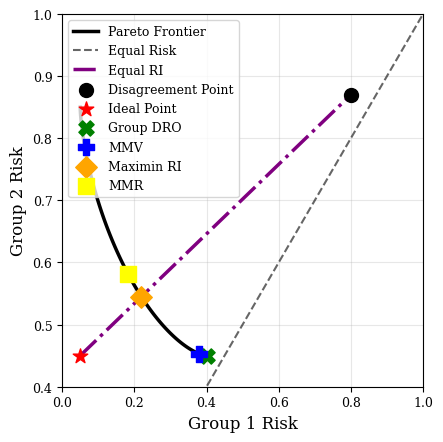

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Set matplotlib parameters for ICML
plt.rcdefaults()
plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9, 'axes.labelsize': 10, 'axes.titlesize': 11,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 8, 'lines.linewidth': 0.75,
})

# Synthetic Pareto frontier
r1_star = 0.05
r2_star = 0.45
t = np.linspace(0,1,100)
pareto_r1 = r1_star + 0.35 * (1-t) ** 1.5
pareto_r2 = r2_star + 0.4 * t ** 1.5

# Disagreement point (baseline)
disagreement_pt = (0.8, 0.87)

naive_idx = np.argmin(pareto_r1 + pareto_r2)
naive_pt = (pareto_r1[naive_idx], pareto_r2[naive_idx])

minimax_idx = np.argmin(np.maximum(pareto_r1, pareto_r2))
minimax_pt = (pareto_r1[minimax_idx], pareto_r2[minimax_idx])

# Recalculate relative improvement from disagreement point
rel_imp_1 = (disagreement_pt[0] - pareto_r1) / (disagreement_pt[0] - r1_star)
rel_imp_2 = (disagreement_pt[1] - pareto_r2) / (disagreement_pt[1] - r2_star)
minimax_rel_imp = np.minimum(rel_imp_1, rel_imp_2)
minimax_rel_idx = np.argmax(minimax_rel_imp)
minimax_rel_pt = (pareto_r1[minimax_rel_idx], pareto_r2[minimax_rel_idx])

regret_1 = pareto_r1 - r1_star
regret_2 = pareto_r2 - r2_star
minimax_reg = np.maximum(regret_1, regret_2)
minimax_reg_idx = np.argmin(minimax_reg)
minimax_reg_pt = (pareto_r1[minimax_reg_idx], pareto_r2[minimax_reg_idx])

reward_1 = disagreement_pt[0] - pareto_r1
reward_2 = disagreement_pt[1] - pareto_r2
minimax_rew = np.minimum(reward_1, reward_2)
minimax_rew_idx = np.argmax(minimax_rew)
minimax_rew_pt = (pareto_r1[minimax_rew_idx], pareto_r2[minimax_rew_idx])

data = {
    'pareto_r1': pareto_r1,
    'pareto_r2': pareto_r2,
    'r1_star': r1_star,
    'r2_star': r2_star,
    'disagreement': disagreement_pt,
    'naive': naive_pt,
    'minimax': minimax_pt,
    'minimax_rew': minimax_rew_pt,
    'minimax_rel': minimax_rel_pt,
    'minimax_rel_val': minimax_rel_imp[minimax_rel_idx],
    'minimax_reg': minimax_reg_pt,
    'reg_1': regret_1,
    'reg_2': regret_2
}

fig, ax1 = plt.subplots(figsize=(4.5, 4.5))
ax1.set_xlim(0.0, 1.0)
ax1.set_ylim(0.4, 1.0)
ax1.plot(data['pareto_r1'], data['pareto_r2'], 'k-', linewidth=2.5, label='Pareto Frontier')
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.6, linewidth=1.5, label='Equal Risk')

# Equal relative improvement line from disagreement point through ideal point
ax1.plot([data['r1_star'], data['disagreement'][0]], 
         [data['r2_star'], data['disagreement'][1]], 
         color='purple', linewidth=2.5, linestyle='-.', 
         label='Equal RI')

# Plot disagreement point
ax1.scatter(*data['disagreement'], color='black', s=100, label='Disagreement Point', zorder=5)

ax1.scatter(data['r1_star'], data['r2_star'], color='red', s=120, 
            marker='*', label='Ideal Point', zorder=5)
ax1.scatter(*data['minimax'], color='green', s=120, marker='X', 
            label='Group DRO', zorder=5)
ax1.scatter(*data['minimax_rew'], color='blue', s=120, marker='P', 
            label='MMV', zorder=5)
ax1.scatter(*data['minimax_rel'], color='orange', s=120, marker='D', 
            label='Maximin RI', zorder=5)
ax1.scatter(*data['minimax_reg'], color='yellow', s=120, marker='s', 
            label='MMR', zorder=5)
ax1.set_xlabel('Group 1 Risk', fontsize=12)
ax1.set_ylabel('Group 2 Risk', fontsize=12)
# No title - following ICML guidelines
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fairness_methods_comparison.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Figure 6: risk space and relative improvement space

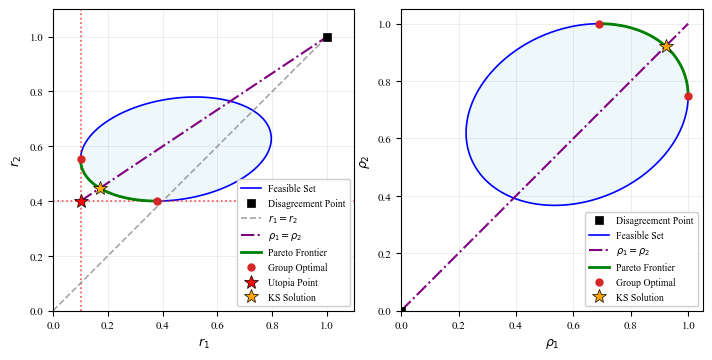

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rc

# Set up ICML-style formatting
plt.rcdefaults()
matplotlib.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'text.usetex': False,  # Set to True if you have LaTeX installed
    'figure.figsize': (7, 3.5),  # ICML two-column width
    'axes.linewidth': 0.8,
    'grid.linewidth': 0.5,
    'lines.linewidth': 1.5,
})

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.5))

# RIGHT PANEL: RELATIVE ACCURACY SPACE (original ellipse)
# Parameters for a tilted ellipse that's tangent to boundaries
center_x, center_y = 0.65, 0.65
a, b = 0.4, 0.3  # semi-major and semi-minor axes
theta = np.pi/8  # rotation angle (22.5 degrees)

# Parametric equations for tilted ellipse
t = np.linspace(0, 2*np.pi, 1000)
# Standard ellipse
x_std = a * np.cos(t)
y_std = b * np.sin(t)

# Apply rotation and translation
rho1 = center_x + x_std * np.cos(theta) - y_std * np.sin(theta)
rho2 = center_y + x_std * np.sin(theta) + y_std * np.cos(theta)

# Adjust to ensure it fits nicely in [0,1] x [0,1]
max_rho1_idx = np.argmax(rho1)
max_rho2_idx = np.argmax(rho2)
shift_x = 1.0 - rho1[max_rho1_idx]
shift_y = 1.0 - rho2[max_rho2_idx]
rho1 = rho1 + shift_x
rho2 = rho2 + shift_y

# Define Bayes risks for transformation
r1_star, r2_star = 0.1, 0.4

# Right panel: Add disagreement point
ax2.plot(0, 0, 's', color='black', markersize=6,
         markeredgecolor='black', markeredgewidth=0.5,
         label='Disagreement Point', zorder=5)

# Apply inverse transformation: r_g = 1 - ρ_g * (1 - r_g*)
r1 = 1 - rho1 * (1 - r1_star)
r2 = 1 - rho2 * (1 - r2_star)

# Find fairness optimal point in relative accuracy space (intersection with diagonal)
diagonal_intersections = []
for i in range(len(rho1)):
    if abs(rho1[i] - rho2[i]) < 0.02 and 0 <= rho1[i] <= 1:
        diagonal_intersections.append((rho1[i], rho2[i], i))

fairness_optimal_rho = None
fairness_optimal_r = None
if diagonal_intersections:
    # Find the best diagonal point (maximum value on diagonal)
    best_diag = max(diagonal_intersections, key=lambda p: min(p[0], p[1]))
    fairness_optimal_rho = (best_diag[0], best_diag[1])
    
    # Calculate T^(-1) transformation of fairness optimal point
    fairness_r1 = 1 - best_diag[0] * (1 - r1_star)
    fairness_r2 = 1 - best_diag[1] * (1 - r2_star)
    fairness_optimal_r = (fairness_r1, fairness_r2)

# Plot relative accuracy space
ax2.plot(rho1, rho2, 'b-', linewidth=1.2, label='Feasible Set')
ax2.fill(rho1, rho2, alpha=0.2, color='lightblue')

# Fairness diagonal
ax2.plot([0, 1], [0, 1], color='purple', linestyle='-.', linewidth=1.5, 
         label=r'$\rho_1 = \rho_2$')

# Pareto frontier in relative accuracy space (upper-right)
valid_indices = (rho1 >= 0) & (rho1 <= 1) & (rho2 >= 0) & (rho2 <= 1)
rho1_valid = rho1[valid_indices]
rho2_valid = rho2[valid_indices]

sorted_indices = np.argsort(rho1_valid)
rho1_sorted = rho1_valid[sorted_indices]
rho2_sorted = rho2_valid[sorted_indices]

pareto_rho1, pareto_rho2 = [], []
max_rho2 = -float('inf')
for i in range(len(rho1_sorted)-1, -1, -1):
    if rho2_sorted[i] > max_rho2:
        max_rho2 = rho2_sorted[i]
        pareto_rho1.insert(0, rho1_sorted[i])
        pareto_rho2.insert(0, rho2_sorted[i])

ax2.plot(pareto_rho1, pareto_rho2, 'green', linewidth=2, label='Pareto Frontier')

# Group optimal points
group1_opt_idx = np.argmax(rho1)
group2_opt_idx = np.argmax(rho2)
ax2.plot(rho1[group1_opt_idx], rho2[group1_opt_idx], 'o', color='C3', 
         markersize=5, label='Group Optimal')
ax2.plot(rho1[group2_opt_idx], rho2[group2_opt_idx], 'o', color='C3', markersize=5)

# Fairness optimal point
if fairness_optimal_rho:
    ax2.plot(fairness_optimal_rho[0], fairness_optimal_rho[1], '*', color='orange', 
             markersize=10, markeredgecolor='black', markeredgewidth=0.5,
             label='KS Solution')

ax2.set_xlim(0, 1.05)
ax2.set_ylim(0, 1.05)
ax2.set_xlabel(r'$\rho_1$', fontsize=9)
ax2.set_ylabel(r'$\rho_2$ ', fontsize=9)
# ax2.set_title('Relative Improvement Space', fontsize=10, pad=8)
ax2.grid(True, alpha=0.3, linewidth=0.5)
ax2.legend(fontsize=7, framealpha=0.95, loc='lower right')
ax2.set_aspect('equal')

# LEFT PANEL: RISK SPACE using T^(-1) transformation
# Plot risk space
ax1.plot(r1, r2, 'b-', linewidth=1.2, label='Feasible Set')
ax1.fill(r1, r2, alpha=0.2, color='lightblue')

# Left panel: Add disagreement point
ax1.plot(1, 1, 's', color='black', markersize=6, 
         markeredgecolor='black', markeredgewidth=0.5,
         label='Disagreement Point', zorder=5)

# Plot Bayes risks
ax1.axvline(x=r1_star, color='red', linestyle=':', linewidth=1.2, alpha=0.7)
ax1.axhline(y=r2_star, color='red', linestyle=':', linewidth=1.2, alpha=0.7)
#ax1.plot([], [], 'r:', linewidth=1.2, label='Bayes Risks')

# Equal risk line
ax1.plot([0, 1], [0, 1], 'gray', linestyle='--', linewidth=1.2, alpha=0.7, 
         label=r'$r_1 = r_2$')

# PURPLE LINE: Equal Relative Accuracy (connects utopia point to (1,1))
ax1.plot([r1_star, 1], [r2_star, 1], color='purple', linewidth=1.5, linestyle='-.', 
         label=r'$\rho_1 = \rho_2$')

# Pareto frontier in risk space (lower-left boundary)
sorted_indices = np.argsort(r1)
r1_sorted = r1[sorted_indices]
r2_sorted = r2[sorted_indices]

pareto_r1, pareto_r2 = [], []
min_r2 = float('inf')
for i in range(len(r1_sorted)):
    if r2_sorted[i] < min_r2:
        min_r2 = r2_sorted[i]
        pareto_r1.append(r1_sorted[i])
        pareto_r2.append(r2_sorted[i])

ax1.plot(pareto_r1, pareto_r2, 'green', linewidth=2, label='Pareto Frontier')

# Transform optimal points back to risk space
r1_group1_opt = 1 - rho1[group1_opt_idx] * (1 - r1_star)
r2_group1_opt = 1 - rho2[group1_opt_idx] * (1 - r2_star)
r1_group2_opt = 1 - rho1[group2_opt_idx] * (1 - r1_star)
r2_group2_opt = 1 - rho2[group2_opt_idx] * (1 - r2_star)

ax1.plot(r1_group1_opt, r2_group1_opt, 'o', color='C3', markersize=5, 
         label='Group Optimal')
ax1.plot(r1_group2_opt, r2_group2_opt, 'o', color='C3', markersize=5)

# Utopia point
ax1.plot(r1_star, r2_star, '*', color='red', markersize=10, 
         markeredgecolor='black', markeredgewidth=0.5, label='Utopia Point')

# Fairness optimal point in risk space
if fairness_optimal_r:
    ax1.plot(fairness_optimal_r[0], fairness_optimal_r[1], '*', color='orange', 
             markersize=10, markeredgecolor='black', markeredgewidth=0.5,
             label='KS Solution')

ax1.set_xlim(0, 1.1)
ax1.set_ylim(0, 1.1)
ax1.set_xlabel(r'$r_1$', fontsize=9)
ax1.set_ylabel(r'$r_2$', fontsize=9)
#ax1.set_title('Risk Space', fontsize=10, pad=8)
ax1.grid(True, alpha=0.3, linewidth=0.5)
ax1.legend(fontsize=7, framealpha=0.95, loc='lower right')
ax1.set_aspect('equal')

plt.tight_layout(pad=0.3)
plt.savefig('ellipse_comparison.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Figure 7: bargaining solutions

Plots saved successfully!


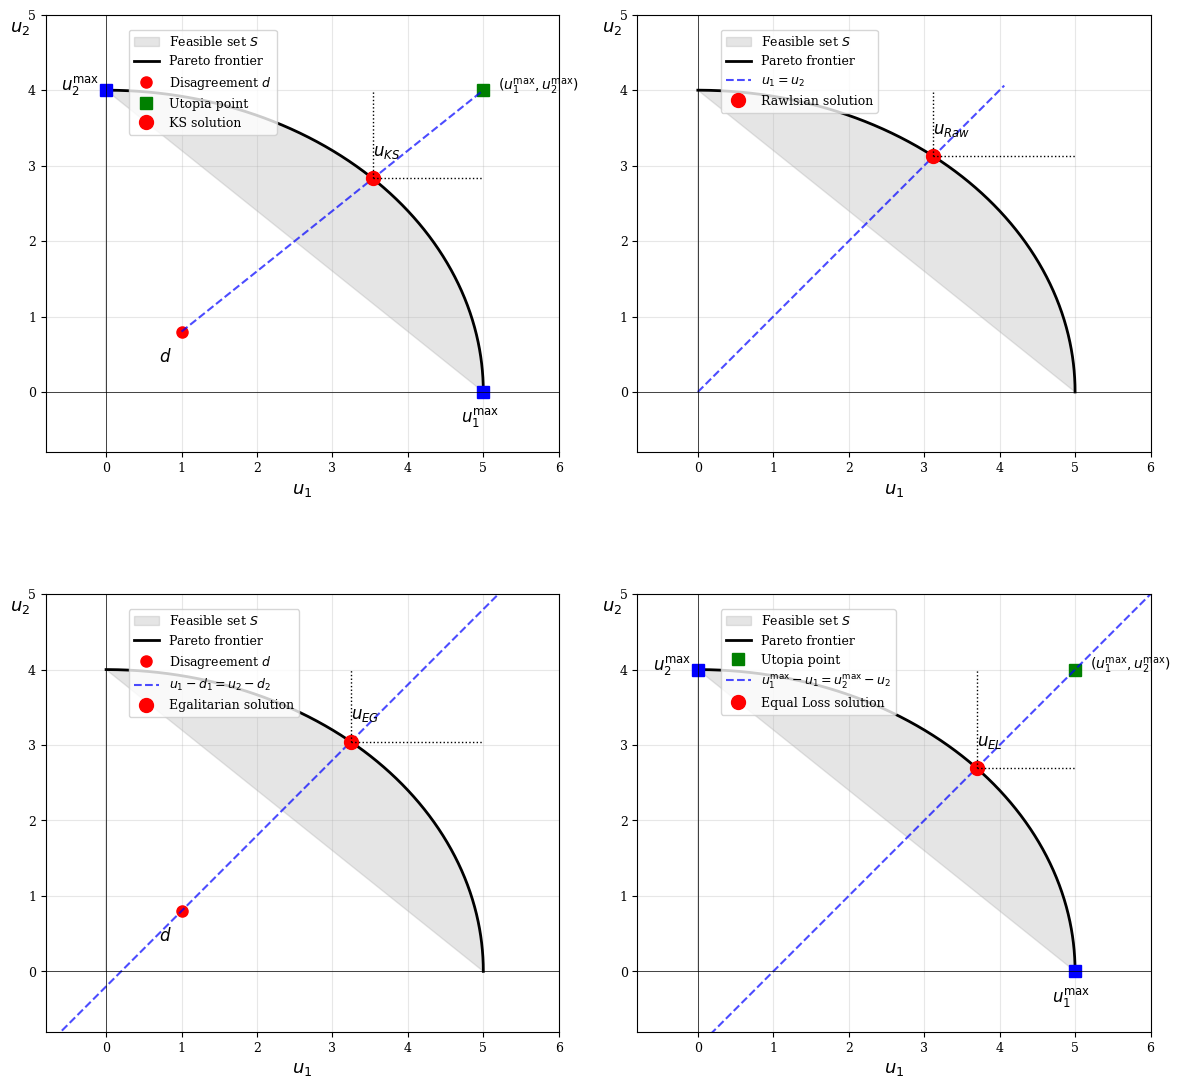

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Set up the plot style
plt.rcdefaults()
plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9, 'axes.labelsize': 10, 'axes.titlesize': 11,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 8, 'lines.linewidth': 0.75,
})
plt.rcParams['font.size'] = 11

# Create figure with 2x2 subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

def plot_bargaining_solution(ax, title, solution_type):
    """
    Plot a bargaining solution diagram
    
    solution_type: 'KS', 'Raw', 'EG', 'EL'
    """
    
    # Define the feasible set (Pareto frontier as an ellipse)
    theta = np.linspace(0, np.pi/2, 1000)
    radius1, radius2 = 5, 4  # Different radii for x and y to create ellipse
    
    # Pareto frontier (ellipse arc)
    u1_curve = radius1 * np.cos(theta)
    u2_curve = radius2 * np.sin(theta)
    
    # Complete the feasible set
    u1_full = np.concatenate([[0], u1_curve, [0]])
    u2_full = np.concatenate([[radius2], u2_curve, [0]])
    
    # Fill the feasible set
    ax.fill(u1_full, u2_full, alpha=0.2, color='gray', label='Feasible set $S$')
    
    # Plot Pareto frontier
    ax.plot(u1_curve, u2_curve, 'k-', linewidth=2, label='Pareto frontier')
    
    # Disagreement point (for KS, EG, YU)
    d1, d2 = 1.0, 0.8
    
    # Ideal points (for KS and YU) - these are the endpoints of Pareto frontier
    u1_max = radius1  # Maximum u1 is at (radius1, 0)
    u2_max = radius2  # Maximum u2 is at (0, radius2)
    
    if solution_type == 'KS':
        # Kalai-Smorodinsky solution
        # Draw disagreement point
        ax.plot(d1, d2, 'ro', markersize=8, label='Disagreement $d$')
        ax.text(d1-0.3, d2-0.4, '$d$', fontsize=12)
        
        # Draw ideal points at the correct locations
        ax.plot([u1_max], [0], 'bs', markersize=8)
        ax.plot([0], [u2_max], 'bs', markersize=8)
        ax.text(u1_max-0.3, -0.4, '$u_1^{\\max}$', fontsize=12)
        ax.text(-0.6, u2_max, '$u_2^{\\max}$', fontsize=12)
        
        # Draw utopia point (u1_max, u2_max)
        ax.plot([u1_max], [u2_max], 'gs', markersize=8, label='Utopia point')
        ax.text(u1_max+0.2, u2_max, '$(u_1^{\\max}, u_2^{\\max})$', fontsize=10)
        
        # KS solution: line from d through (u1_max, u2_max) to Pareto frontier
        # Direction vector from d to (u1_max, u2_max)
        dir_u1 = u1_max - d1
        dir_u2 = u2_max - d2
        
        t_vals = np.linspace(0, 3, 1000)
        line_u1 = d1 + t_vals * dir_u1
        line_u2 = d2 + t_vals * dir_u2
        
        # Find intersection with ellipse Pareto frontier
        ks_u1, ks_u2 = None, None
        for i in range(len(line_u1)):
            ellipse_val = (line_u1[i]/radius1)**2 + (line_u2[i]/radius2)**2
            if ellipse_val >= 0.99:
                # Find closest point on ellipse
                best_dist = float('inf')
                for j in range(len(u1_curve)):
                    dist = (line_u1[i] - u1_curve[j])**2 + (line_u2[i] - u2_curve[j])**2
                    if dist < best_dist:
                        best_dist = dist
                        ks_u1, ks_u2 = u1_curve[j], u2_curve[j]
                break
        
        # Draw line from d through (u1_max, u2_max) to solution
        # First, draw from d to solution
        ax.plot([d1, u1_max], [d2, u2_max], 'b--', linewidth=1.5, alpha=0.7)
        
        ax.plot(ks_u1, ks_u2, 'ro', markersize=10, label='KS solution')
        ax.text(ks_u1, ks_u2+0.3, '$u_{KS}$', fontsize=12, fontweight='bold')
        
        # Add proportion lines (showing equal relative gains)
        ax.plot([ks_u1, u1_max], [ks_u2, ks_u2], 'k:', linewidth=1)
        ax.plot([ks_u1, ks_u1], [ks_u2, u2_max], 'k:', linewidth=1)
        
    elif solution_type == 'Raw':
        # Rawlsian (Maximin) solution
        # Solution is where u1 = u2 on the Pareto frontier
        # For ellipse, find where u1 = u2 intersects
        best_i = 0
        min_diff = float('inf')
        for i in range(len(u1_curve)):
            diff = abs(u1_curve[i] - u2_curve[i])
            if diff < min_diff:
                min_diff = diff
                best_i = i
        
        raw_u1, raw_u2 = u1_curve[best_i], u2_curve[best_i]
        
        # Draw the u1 = u2 line
        line_extent = max(raw_u1, raw_u2) * 1.3
        ax.plot([0, line_extent], [0, line_extent], 'b--', linewidth=1.5, alpha=0.7, label='$u_1 = u_2$')
        ax.plot(raw_u1, raw_u2, 'ro', markersize=10, label='Rawlsian solution')
        ax.text(raw_u1, raw_u2+0.3, '$u_{Raw}$', fontsize=12, fontweight='bold')
        
        # Add gain lines
        ax.plot([raw_u1, u1_max], [raw_u2, raw_u2], 'k:', linewidth=1)
        ax.plot([raw_u1, raw_u1], [raw_u2, u2_max], 'k:', linewidth=1)
        
    elif solution_type == 'EG':
        # Egalitarian solution
        ax.plot(d1, d2, 'ro', markersize=8, label='Disagreement $d$')
        ax.text(d1-0.3, d2-0.4, '$d$', fontsize=12)
        
        # Solution: equal gains from disagreement point
        # Find point on Pareto frontier where u1 - d1 = u2 - d2
        best_i = 0
        min_diff = float('inf')
        for i in range(len(u1_curve)):
            diff = abs((u1_curve[i] - d1) - (u2_curve[i] - d2))
            if diff < min_diff:
                min_diff = diff
                best_i = i
        
        eg_u1, eg_u2 = u1_curve[best_i], u2_curve[best_i]
        
        # Draw line through solution: u2 - d2 = u1 - d1, or u2 = u1 - d1 + d2
        # This is a line with slope 1
        line_u1 = np.linspace(-1, 7, 100)
        line_u2 = line_u1 - d1 + d2
        ax.plot(line_u1, line_u2, 'b--', linewidth=1.5, alpha=0.7, label='$u_1 - d_1 = u_2 - d_2$')
        
        ax.plot(eg_u1, eg_u2, 'ro', markersize=10, label='Egalitarian solution')
        ax.text(eg_u1, eg_u2+0.3, '$u_{EG}$', fontsize=12, fontweight='bold')
        
        # Add gain lines
        ax.plot([eg_u1, u1_max], [eg_u2, eg_u2], 'k:', linewidth=1)
        ax.plot([eg_u1, eg_u1], [eg_u2, u2_max], 'k:', linewidth=1) 
        
    elif solution_type == 'EL':
        # Equal Loss solution (equal loss from the utopia point)
        # Draw ideal points at the correct locations
        ax.plot([u1_max], [0], 'bs', markersize=8)
        ax.plot([0], [u2_max], 'bs', markersize=8)
        ax.text(u1_max-0.3, -0.4, '$u_1^{\\max}$', fontsize=12)
        ax.text(-0.6, u2_max, '$u_2^{\\max}$', fontsize=12)
        
        # Draw utopia point (u1_max, u2_max)
        ax.plot([u1_max], [u2_max], 'gs', markersize=8, label='Utopia point')
        ax.text(u1_max+0.2, u2_max, '$(u_1^{\\max}, u_2^{\\max})$', fontsize=10)
        
        # Equal loss: (u1_max - u1) = (u2_max - u2)
        # Find point where (u1_max - u1) = (u2_max - u2)
        # This means u1 + u2 = u1_max + u2_max = constant
        best_i = 0
        min_diff = float('inf')
        for i in range(len(u1_curve)):
            diff = abs((u1_max - u1_curve[i]) - (u2_max - u2_curve[i]))
            if diff < min_diff:
                min_diff = diff
                best_i = i
        
        yu_u1, yu_u2 = u1_curve[best_i], u2_curve[best_i]
        
        # Draw line from (u1_max, u2_max) through the EL solution
        # Direction from (u1_max, u2_max) to origin has slope -u2_max/u1_max
        # But we want the line through the EL solution with slope 1
        # Line equation: u2 = u1 + (-u1_max + u2_max)
        line_u1 = np.linspace(-1, u1_max+1, 100)
        line_u2 = line_u1 - (u1_max - u2_max)
        ax.plot(line_u1, line_u2, 'b--', linewidth=1.5, alpha=0.7, label='$u_1^{\\max} - u_1 = u_2^{\\max} - u_2$')
        
        ax.plot(yu_u1, yu_u2, 'ro', markersize=10, label='Equal Loss solution')
        ax.text(yu_u1, yu_u2+0.3, '$u_{EL}$', fontsize=12, fontweight='bold')
        
        # Add regret lines - horizontal and vertical from solution
        ax.plot([yu_u1, u1_max], [yu_u2, yu_u2], 'k:', linewidth=1)
        ax.plot([yu_u1, yu_u1], [yu_u2, u2_max], 'k:', linewidth=1)
    
    # Set labels and limits
    ax.set_xlabel('$u_1$', fontsize=13)
    ax.set_ylabel('$u_2$', fontsize=13, rotation=0)
    ax.yaxis.set_label_coords(-0.05, 0.95)
    ax.set_xlim(-0.8, 6)
    ax.set_ylim(-0.8, 5)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    # ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9, bbox_to_anchor=(0.15, 0.98))
    
    # Draw axes
    ax.axhline(y=0, color='k', linewidth=0.5)
    ax.axvline(x=0, color='k', linewidth=0.5)

# Plot each solution
plot_bargaining_solution(axes[0, 0], 'Kalai-Smorodinsky (KS) Solution', 'KS')
plot_bargaining_solution(axes[0, 1], 'Rawlsian (Maximin) Solution', 'Raw')
plot_bargaining_solution(axes[1, 0], 'Egalitarian (EG) Solution', 'EG')
plot_bargaining_solution(axes[1, 1], 'Equal Loss (EL) Solution', 'EL')

plt.tight_layout()
plt.savefig('bargaining_solutions.pdf', bbox_inches='tight')
print("Plots saved successfully!")
plt.show()